# Mouse epithelial: cell-type annotation (stage 04c)

Every cluster of the re-integrated epithelial lineage is assigned one cell type (or EXCLUDE). Labels are the vocabulary in resources/annotation_vocabulary.yaml.

Clustering: `data/interim/latent_mouse_epithelial.h5ad`, column `leiden_scVI_3.0`. Decisions: `resources/annotations/mouse_epithelial.csv`, one
row per cluster with the markers that justify the label in `note`. Nothing in this
notebook assigns a label; it shows the evidence the table was decided from.

In [1]:
import warnings
from pathlib import Path

import anndata as ad
import numpy as np
import pandas as pd
import scanpy as sc

# Notebook kernels start in notebooks/annotation/, so the repo root is two levels up.
REPO = Path("../..").resolve()
if not (REPO / "resources/annotations").is_dir():
    raise FileNotFoundError(f"{REPO} is not the repository root")
SPECIES, LEVEL, RESOLUTION = "mouse", "epithelial", "leiden_scVI_3.0"
OBJECT = REPO / "data/interim/latent_mouse_epithelial.h5ad"
TABLE = REPO / "resources/annotations/mouse_epithelial.csv"
PANEL = ['Cdh1', 'Pax8', 'Wnt7a', 'Muc1', 'Lgr5', 'Foxa2', 'Ihh', 'Lif', 'Flt1', 'Pecam1', 'Pdgfra', 'Prl8a2', 'Acta2', 'Myh11', 'Ptprc', 'Sox6', 'Prss28', 'Prss29', 'Foxj1', 'Mki67', 'Top2a', 'Epcam']
sc.settings.set_figure_params(dpi=80, frameon=False)
pd.set_option("display.max_colwidth", 200)

## 1. The committed table

In [2]:
table = pd.read_csv(TABLE, dtype={"cluster": str})
table.set_index("cluster")

,label,n_cells,res,note
cluster,,,,
0,epithelial_cell,157,leiden_scVI_3.0,"Cdh1 0.69; Pax8 0.86; Wnt7a 0.09; Foxa2 0.11 | top vs level: Syn2 0.96, Ryr3 0.85, Dnm3 0.81"
1,epithelial_luminal,156,leiden_scVI_3.0,"Wnt7a 0.19; Foxa2 0.02; Prss28 0.01; Cdh1 0.73 | top vs level: Lrp2 0.95, Enpp3 0.96, Etnk1 0.98"
2,epithelial_luminal,256,leiden_scVI_3.0,"Wnt7a 0.26; Foxa2 0.00; Prss28 0.00; Cdh1 0.77 | top vs level: Sdk1 0.96, Zbtb16 0.96, Npl 0.90"
3,epithelial_luminal,428,leiden_scVI_3.0,"Wnt7a 0.14; Foxa2 0.13; Prss28 0.02; Cdh1 0.71 | top vs level: Rims3 0.91, Dnah14 0.87, Mme 0.96"
4,EXCLUDE,173,leiden_scVI_3.0,"EXCLUDE: doublet score med 6.02 (level q75 0.09), genes med 3174 (level q25 1831), 0.84 co-express 2+ lineage panels (level 0.33); panels: epithelial 0.95, immune 0.77, perimetrium 0.30"
5,epithelial_glandular,148,leiden_scVI_3.0,"Foxa2 0.22; Prss28 0.68; Prss29 0.73; Wnt7a 0.03 | top vs level: Tpt1 0.89, Rplp2 0.82, Fth1 0.80"
6,epithelial_glandular,207,leiden_scVI_3.0,"Foxa2 0.14; Prss28 0.17; Prss29 0.27; Wnt7a 0.03 | top vs level: Tshz2 0.88, Dlgap1 0.67, Galntl6 0.91"
7,EXCLUDE,243,leiden_scVI_3.0,"EXCLUDE: doublet score med 0.01 (level q75 0.09), genes med 2422 (level q25 1831), 0.51 co-express 2+ lineage panels (level 0.33); panels: epithelial 0.88, vascular 0.36, endometrial_fibroblasts 0.20"
8,epithelial_luminal,140,leiden_scVI_3.0,"Wnt7a 0.27; Foxa2 0.00; Prss28 0.00; Cdh1 0.86 | top vs level: Sdk1 0.96, Sox5 1.00, Lrp2 0.99"


## 2. The clustered object (must carry exactly the clusters in the table)

In [3]:
adata = ad.read_h5ad(OBJECT)
adata.obs["cluster"] = adata.obs[RESOLUTION].astype(str)
in_object, in_table = set(adata.obs["cluster"]), set(table["cluster"])
if in_object != in_table:
    raise ValueError(f"cluster sets differ: object-only {sorted(in_object - in_table)}, "
                     f"table-only {sorted(in_table - in_object)}")
labels = table.set_index("cluster")["label"]
adata.obs["label"] = adata.obs["cluster"].map(labels).astype("category")
print(adata.n_obs, "nuclei;", len(in_object), "clusters")
print(adata.obs["label"].value_counts().to_dict())

6681 nuclei; 29 clusters
{'epithelial_glandular': 2828, 'epithelial_luminal': 2450, 'epithelial_cell': 987, 'EXCLUDE': 416}


In [4]:
# Expression for the dot plot: CP10K log1p from raw counts.
counts = adata.layers["counts"] if "counts" in adata.layers else adata.X
expr = ad.AnnData(X=counts.copy(), obs=adata.obs[["cluster", "label"]].copy(),
                  var=adata.var[[]].copy())
sc.pp.normalize_total(expr, target_sum=1e4)
sc.pp.log1p(expr)
genes = [g for g in PANEL if g in expr.var_names]
missing = sorted(set(PANEL) - set(genes))
if missing:
    print("not in this object:", missing)

## 3. Marker dot plot by cluster

Dot size is the fraction of nuclei in which the gene is detected, colour the mean
log1p CP10K. Clusters are grouped by their label; EXCLUDE clusters are last.

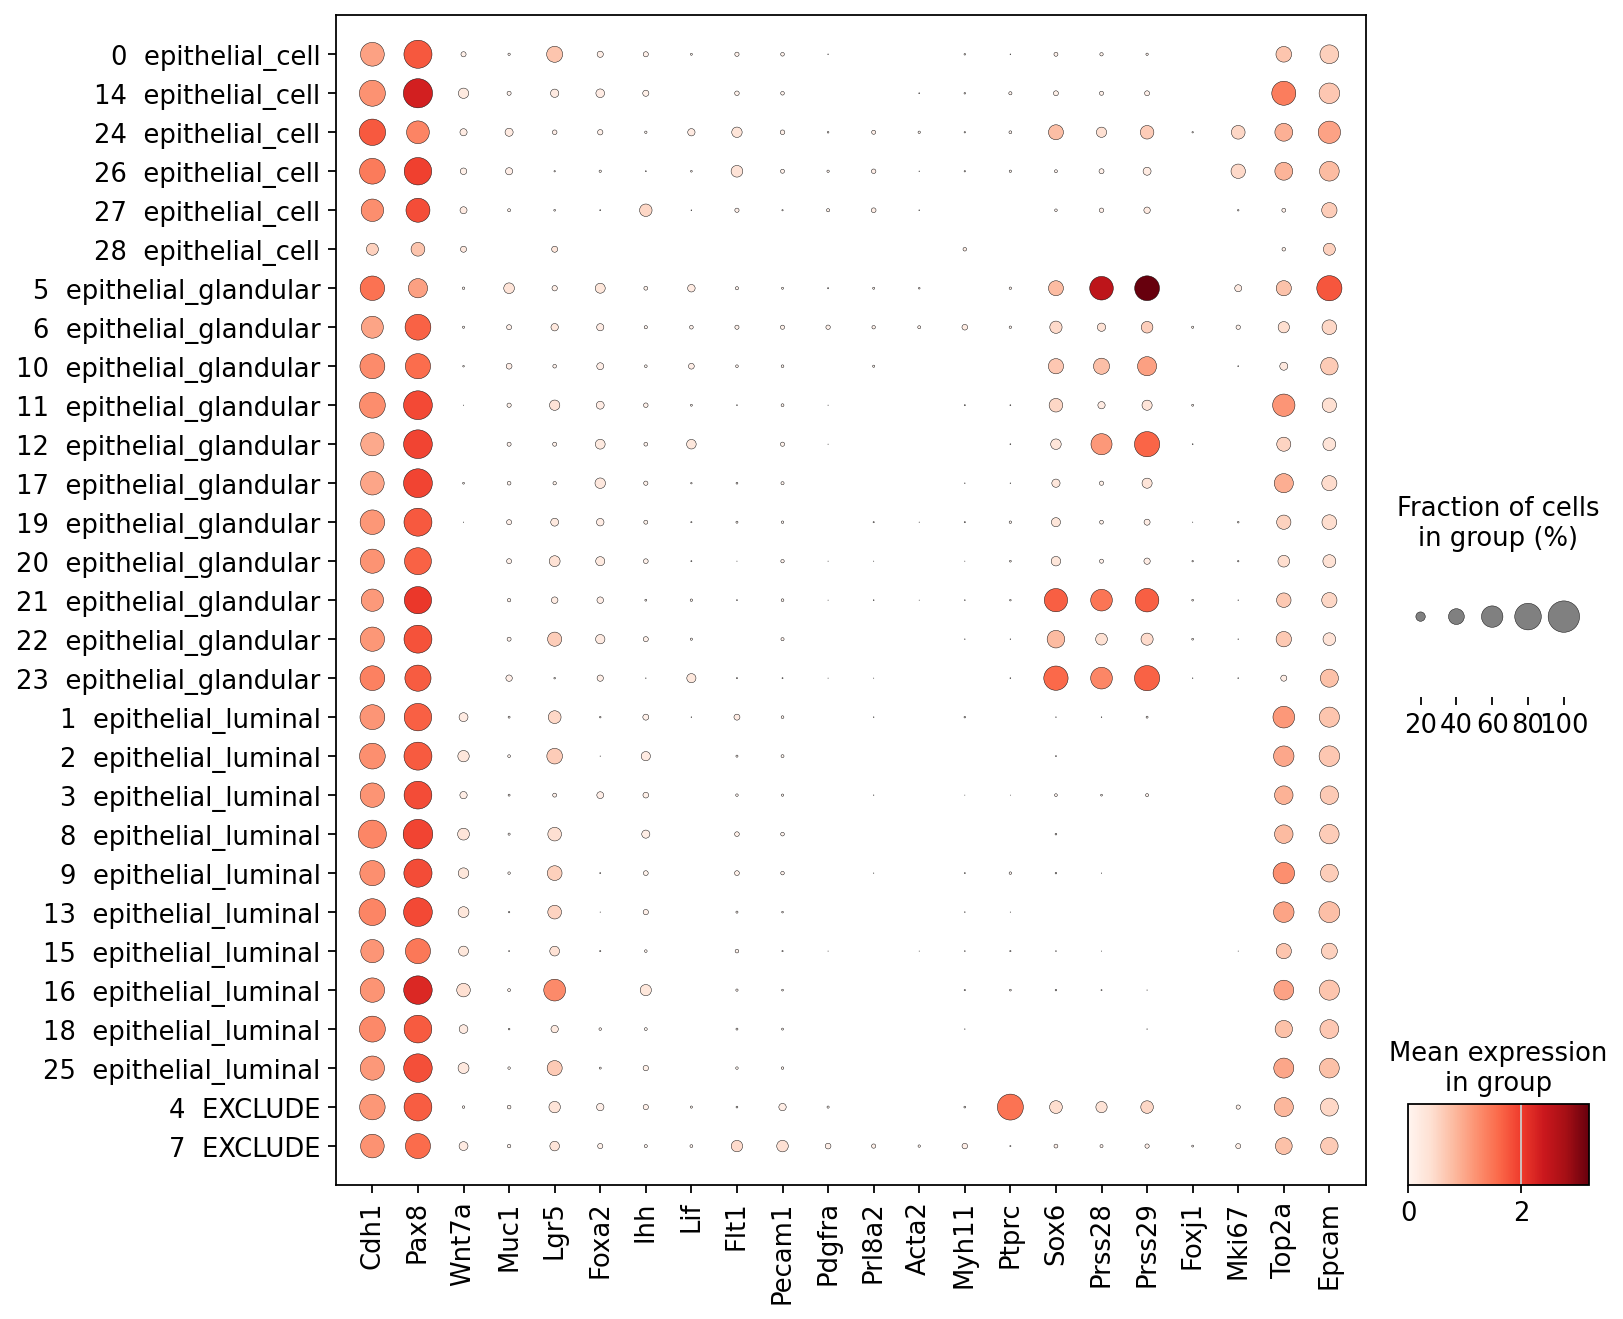

In [5]:
def sort_key(c):
    return (labels[c] == "EXCLUDE", labels[c], int(c) if c.isdigit() else c)

order = sorted(in_object, key=sort_key)
expr.obs["cluster_labelled"] = pd.Categorical(
    [f"{c}  {labels[c]}" for c in expr.obs["cluster"]],
    categories=[f"{c}  {labels[c]}" for c in order])
sc.pl.dotplot(expr, genes, groupby="cluster_labelled", standard_scale=None,
              figsize=(0.32 * len(genes) + 3, 0.28 * len(order) + 1.5))

## 4. QC per cluster

Median DoubletDetection score and genes per nucleus per cluster, with the lineage
median for reference (the CSV notes quote the lineage's doublet 75th and genes 25th
percentiles, from `tools/cluster_marker_table.py`). A high doublet score together
with markers of another lineage (section 6) is what an EXCLUDE call rests on; a
moderate score alone is not (cycling clusters score around 1 throughout this
dataset).

In [6]:
qc_cols = [c for c in ("doubletdetection_doublet_score", "n_genes_by_counts",
                       "total_counts") if c in adata.obs]
qc = adata.obs.groupby("cluster", observed=True)[qc_cols].median().loc[order]
qc.insert(0, "n", adata.obs["cluster"].value_counts().loc[order])
qc.insert(1, "label", labels.loc[order])
qc.loc["lineage median"] = [adata.n_obs, ""] + list(adata.obs[qc_cols].median())
qc.round(2)

,n,label,doubletdetection_doublet_score,n_genes_by_counts,total_counts
cluster,,,,,
0,157,epithelial_cell,0.01,2610.0,5755.0
14,106,epithelial_cell,0.02,2923.5,6617.0
24,245,epithelial_cell,1.02,2356.0,4616.0
26,187,epithelial_cell,1.36,2501.0,4568.0
27,274,epithelial_cell,0.28,1677.5,3415.5
28,18,epithelial_cell,0.00,811.0,1401.0
5,148,epithelial_glandular,0.13,1487.0,2397.5
6,207,epithelial_glandular,0.00,2322.0,4202.0
10,105,epithelial_glandular,0.00,2631.0,5229.0


## 5. UMAP by cluster and by label

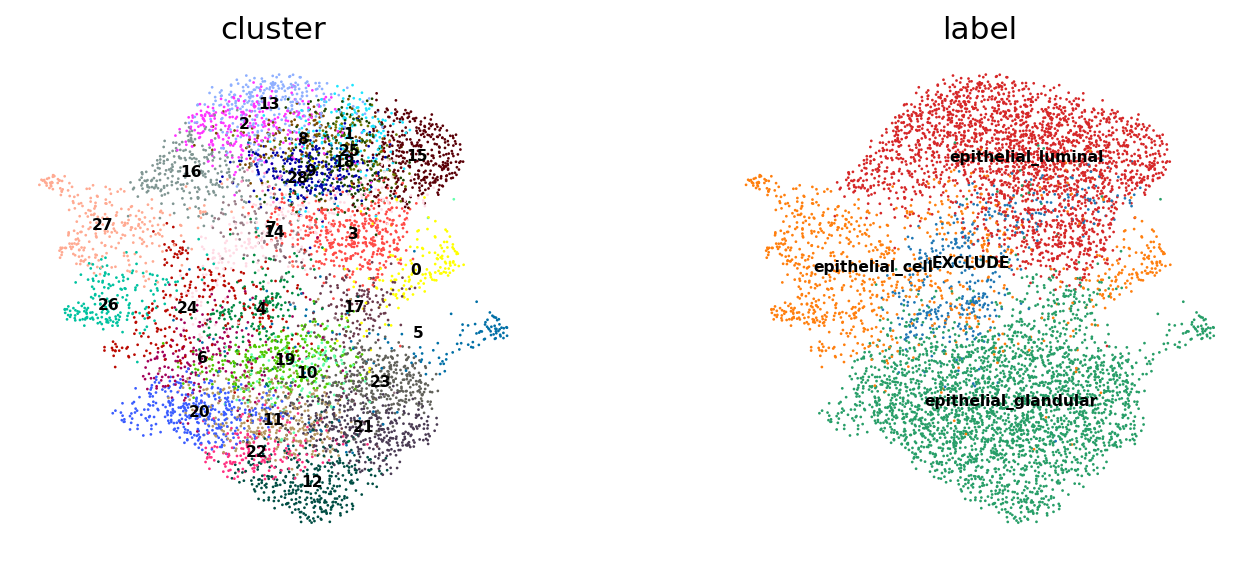

In [7]:
umap_key = next((k for k in ("X_umap_scVI", "X_umap") if k in adata.obsm), None)
if umap_key is None:
    latent_key = next(k for k in adata.obsm if "scVI" in k or "scvi" in k)
    sc.pp.neighbors(adata, use_rep=latent_key, n_neighbors=15, random_state=0)
    sc.tl.umap(adata, random_state=0)
    umap_key = "X_umap"
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    sc.pl.embedding(adata, basis=umap_key, color=["cluster", "label"], legend_loc="on data",
                    legend_fontsize=7, size=6, ncols=2, wspace=0.25)

## 6. EXCLUDE clusters

Detection of each lineage's markers inside the excluded clusters, next to the
lineage-wide detection; a cluster is excluded when it carries another lineage's
programme (doublets) or too little RNA to call.

In [8]:
excluded = [c for c in order if labels[c] == "EXCLUDE"]
if excluded:
    detected = pd.DataFrame(
        {c: np.asarray((expr[expr.obs["cluster"] == c, genes].X > 0).mean(0)).ravel()
         for c in excluded},
        index=genes)
    detected["lineage"] = np.asarray((expr[:, genes].X > 0).mean(0)).ravel()
    display(detected.round(2).T)
else:
    print("no EXCLUDE clusters in this table")

,Cdh1,Pax8,Wnt7a,Muc1,Lgr5,Foxa2,Ihh,Lif,Flt1,Pecam1,...,Acta2,Myh11,Ptprc,Sox6,Prss28,Prss29,Foxj1,Mki67,Top2a,Epcam
4,0.76,0.85,0.03,0.06,0.26,0.14,0.09,0.03,0.02,0.14,...,0.00,0.02,0.77,0.30,0.25,0.29,0.00,0.07,0.51,0.47
7,0.68,0.74,0.19,0.05,0.21,0.09,0.05,0.04,0.26,0.26,...,0.03,0.10,0.01,0.06,0.05,0.07,0.02,0.09,0.43,0.46
lineage,0.72,0.82,0.11,0.06,0.20,0.10,0.09,0.04,0.06,0.05,...,0.01,0.01,0.03,0.19,0.17,0.22,0.01,0.04,0.42,0.45


## 7. Luminal vs glandular (v3)

The split was called per cluster: Wnt7a detected in >= 14% of nuclei with
Foxa2/Prss28/Prss29 each < 8% -> luminal; the reverse -> glandular; clusters
meeting neither rule stay `epithelial_cell`. Detection fractions and the UMAP
of the two axes:

/tmp/ipykernel_3353046/3959306899.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  frac = detected.groupby(expr.obs["cluster"].values).mean().loc[order]


,label,Wnt7a,Foxa2,Prss28,Prss29
0,epithelial_cell,0.09,0.11,0.05,0.03
14,epithelial_cell,0.23,0.18,0.07,0.08
24,epithelial_cell,0.14,0.09,0.22,0.33
26,epithelial_cell,0.12,0.03,0.09,0.16
27,epithelial_cell,0.14,0.01,0.07,0.12
28,epithelial_cell,0.11,0.00,0.00,0.00
5,epithelial_glandular,0.03,0.22,0.68,0.73
6,epithelial_glandular,0.03,0.14,0.17,0.27
10,epithelial_glandular,0.02,0.13,0.41,0.51
11,epithelial_glandular,0.00,0.16,0.14,0.22


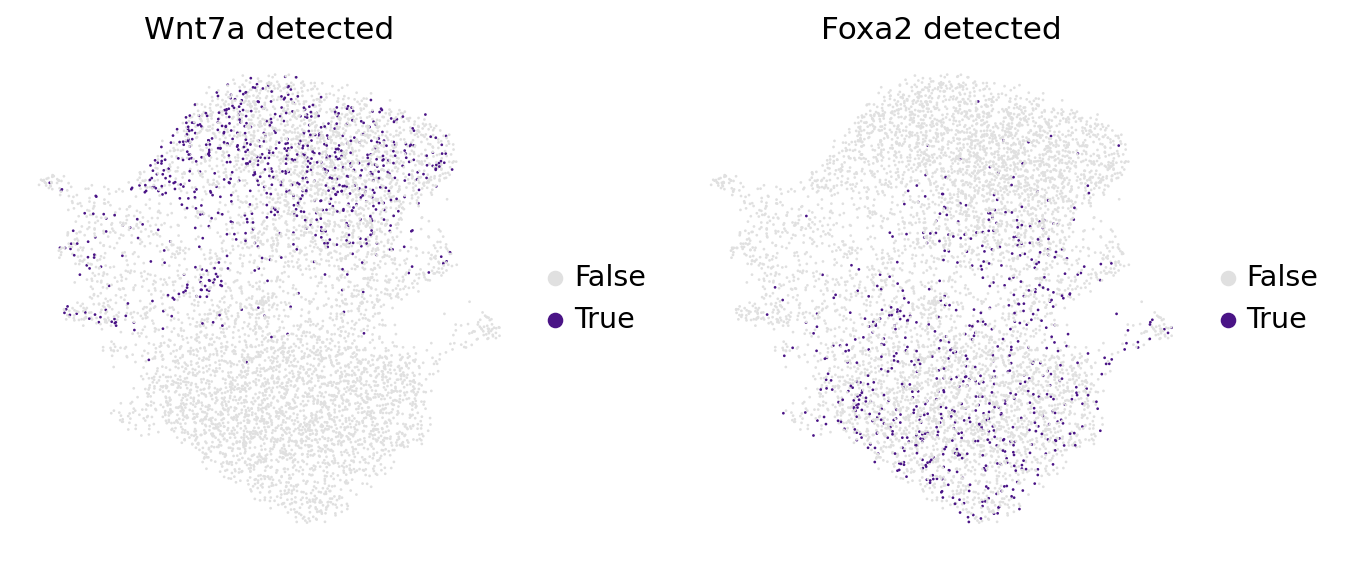

In [9]:
axes_genes = [g for g in ["Wnt7a", "Foxa2", "Prss28", "Prss29"] if g in expr.var_names]
detected = pd.DataFrame(np.asarray((expr[:, axes_genes].X > 0).todense()),
                        columns=axes_genes, index=expr.obs_names)
frac = detected.groupby(expr.obs["cluster"].values).mean().loc[order]
frac.insert(0, "label", labels.loc[order])
display(frac.round(2))
for g in axes_genes[:2]:
    column = np.asarray(counts[:, list(adata.var_names).index(g)].todense()).ravel()
    adata.obs[f"{g} detected"] = (column > 0).astype(str)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    sc.pl.embedding(adata, basis=umap_key, color=[f"{g} detected" for g in axes_genes[:2]],
                    size=6, ncols=2, palette=["#e0e0e0", "#4a1486"])